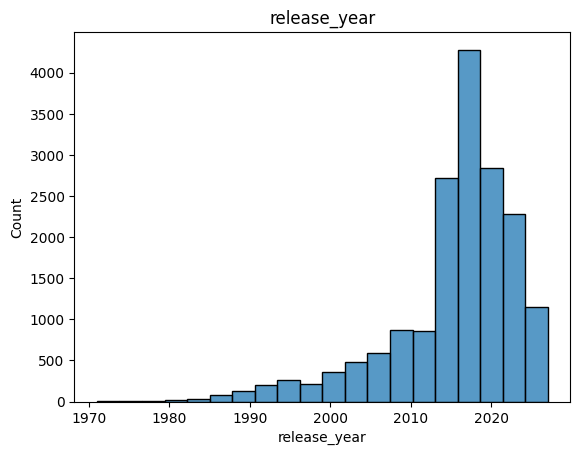

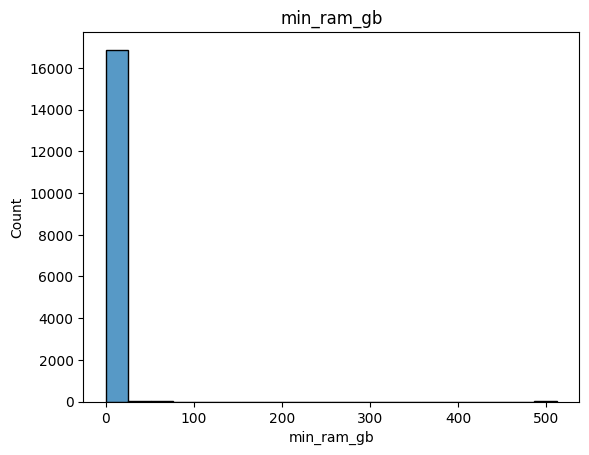

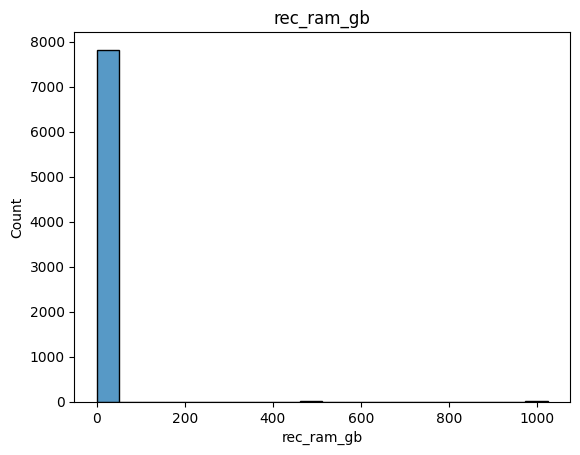

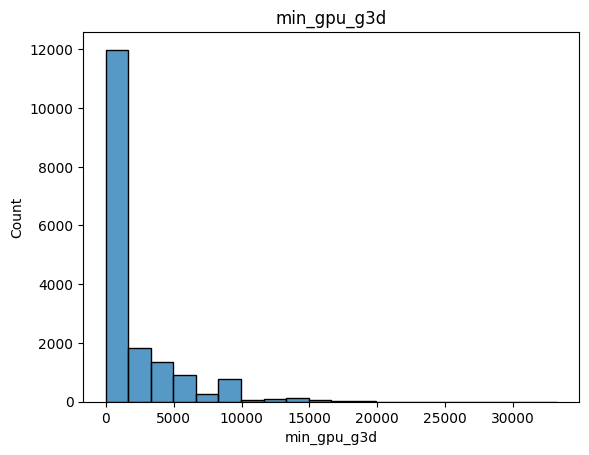

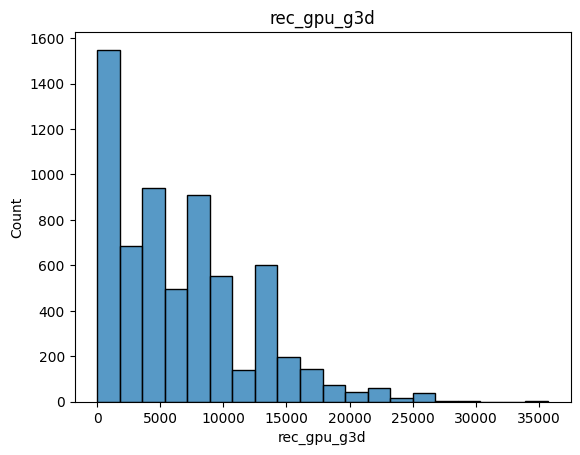

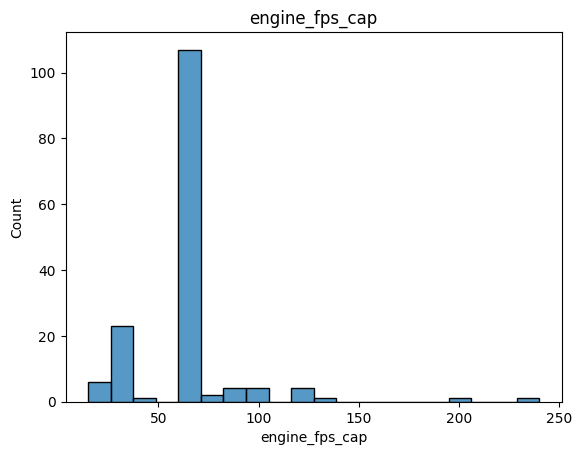

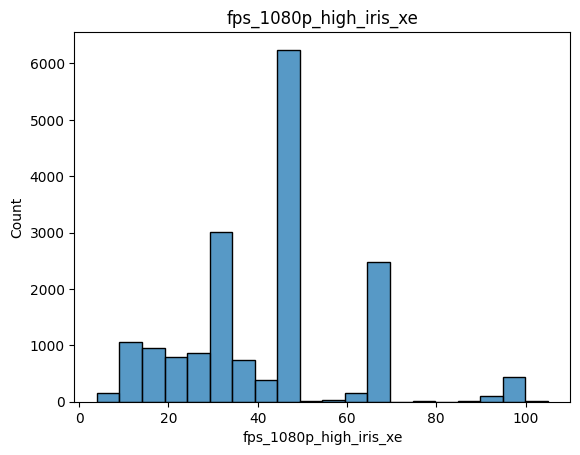

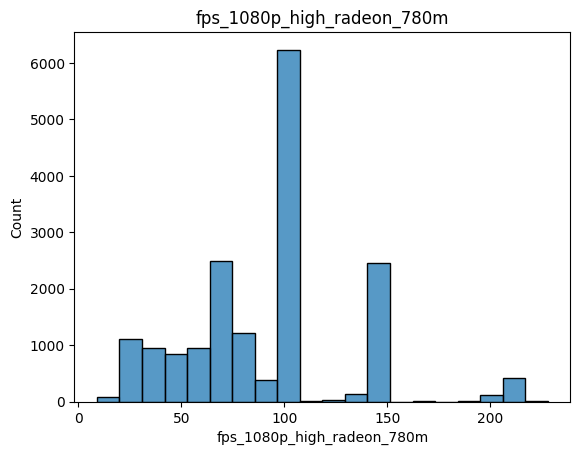

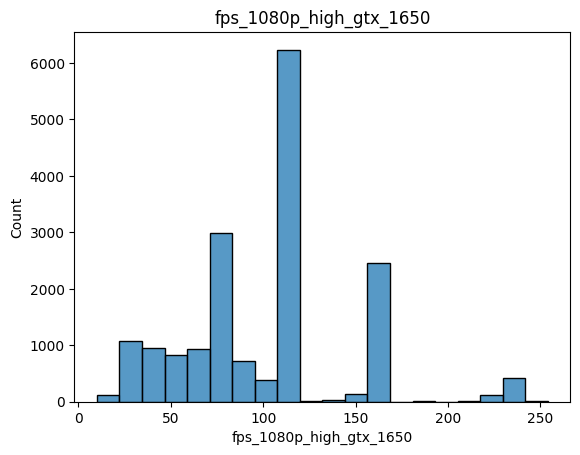

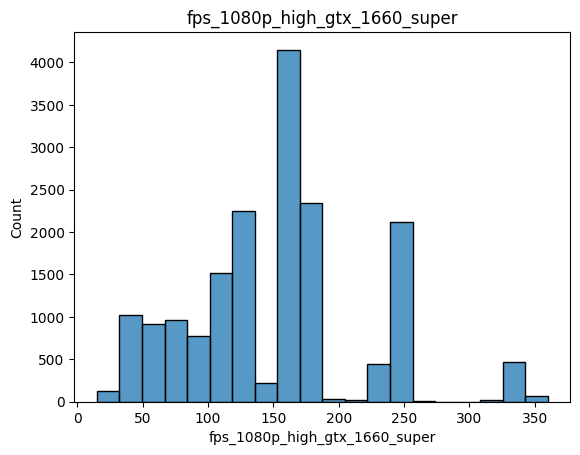

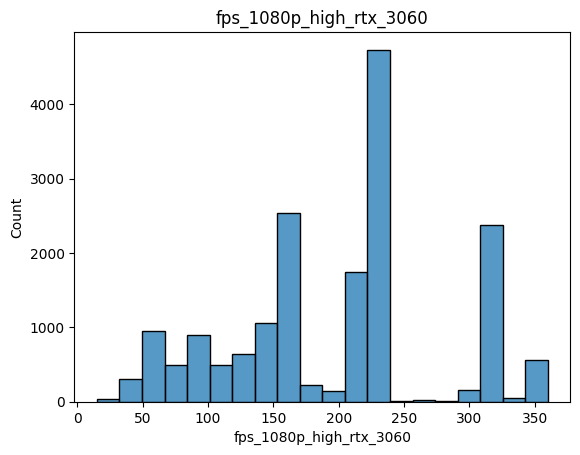

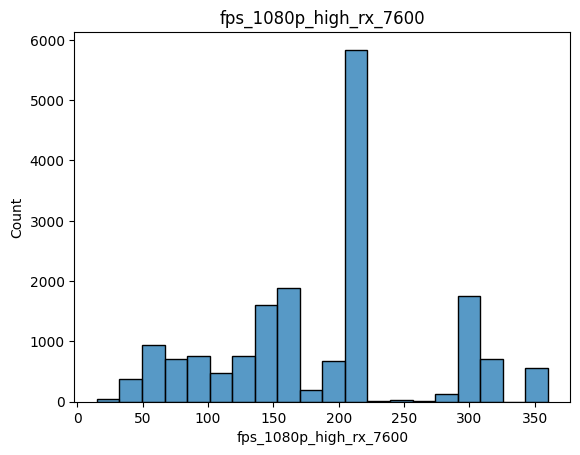

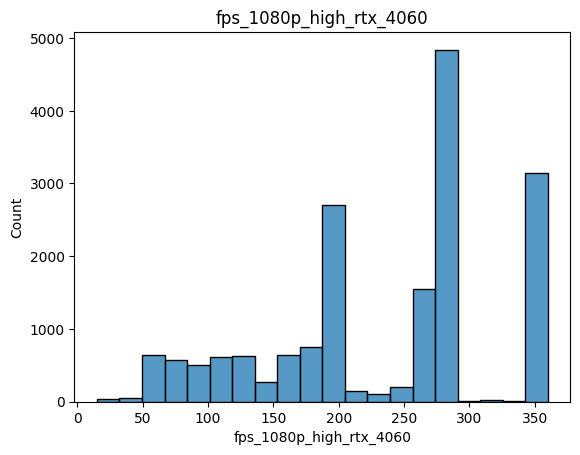

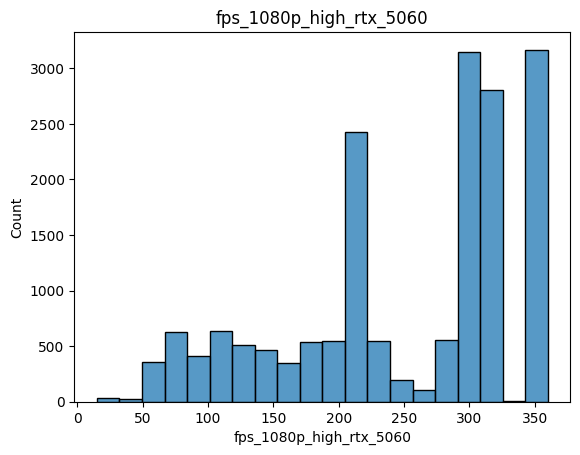

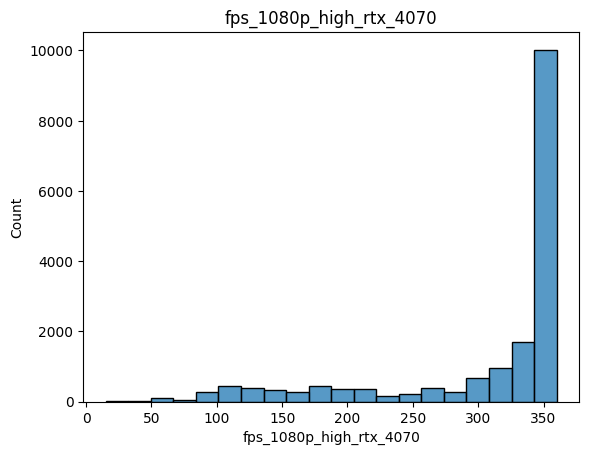

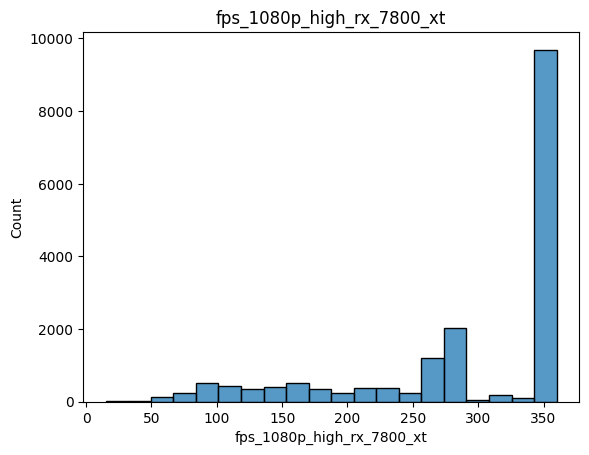

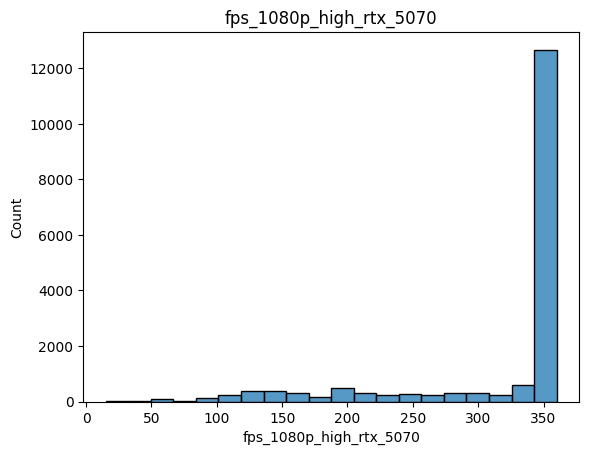

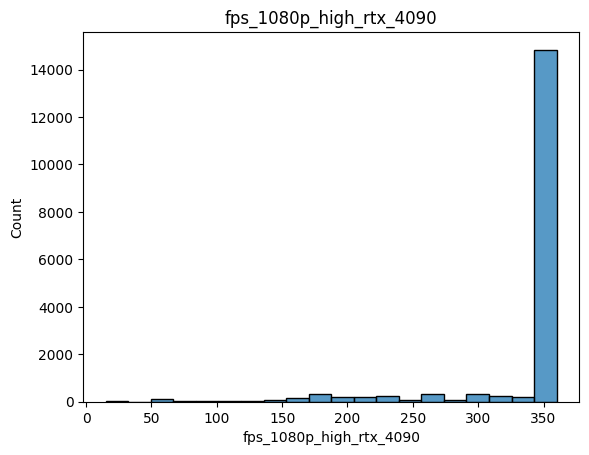

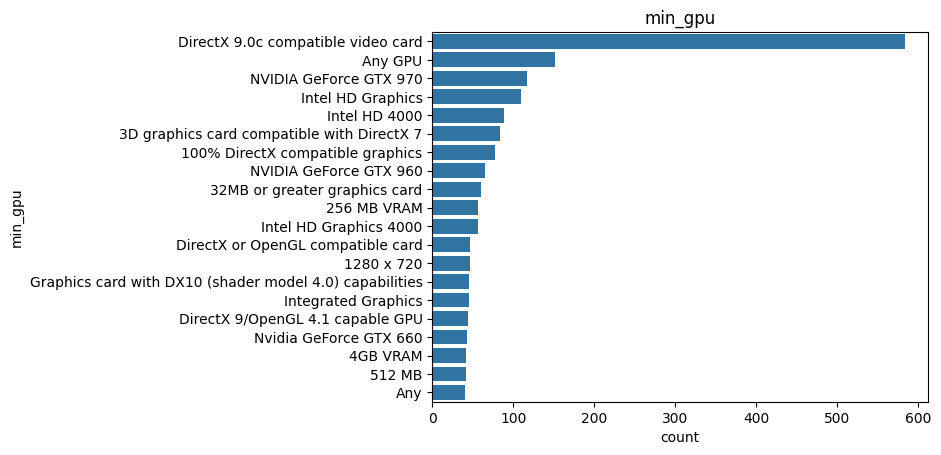

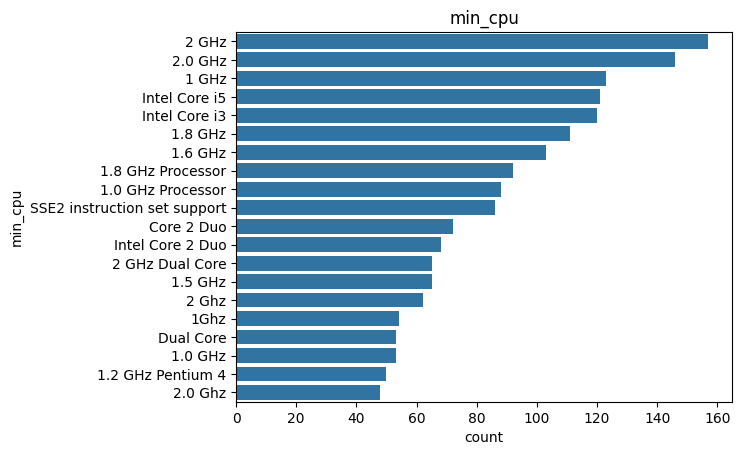

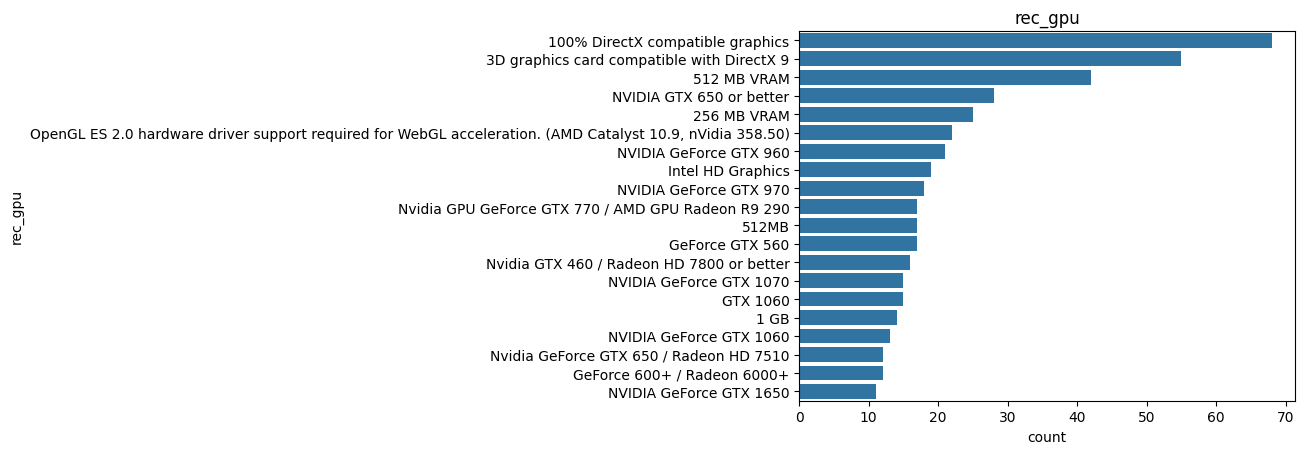

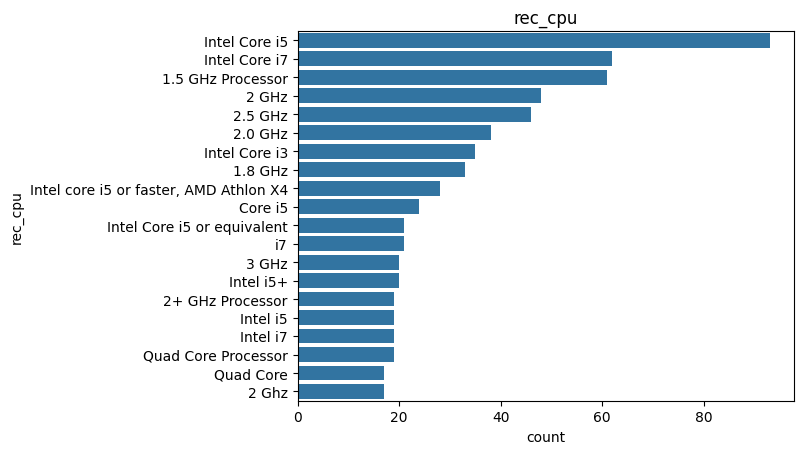


release_year
Max:     2027.0
Min:     1971.0
Mean:    2015.2436597849214
Median:  2017.0
Outliers: 1447

min_ram_gb
Max:     512.0
Min:     0.0
Mean:    3.9048943599455526
Median:  2.0
Outliers: 542

rec_ram_gb
Max:     1024.0
Min:     1.0
Mean:    8.248978027593255
Median:  8.0
Outliers: 1630

min_gpu_g3d
Max:     33194
Min:     1
Mean:    1974.6682733689104
Median:  600.0
Outliers: 1965

rec_gpu_g3d
Max:     35712.0
Min:     5.0
Mean:    6682.777140198511
Median:  5527.0
Outliers: 122

engine_fps_cap
Max:     240.0
Min:     15.0
Mean:    60.27272727272727
Median:  60.0
Outliers: 55

fps_1080p_high_iris_xe
Max:     105
Min:     4
Mean:    42.69885809376255
Median:  46.0
Outliers: 575

fps_1080p_high_radeon_780m
Max:     228
Min:     9
Mean:    92.33976014230791
Median:  100.0
Outliers: 577

fps_1080p_high_gtx_1650
Max:     254
Min:     10
Mean:    103.00969759568486
Median:  111.0
Outliers: 564

fps_1080p_high_gtx_1660_super
Max:     360
Min:     15
Mean:    150.69168531588915
Median

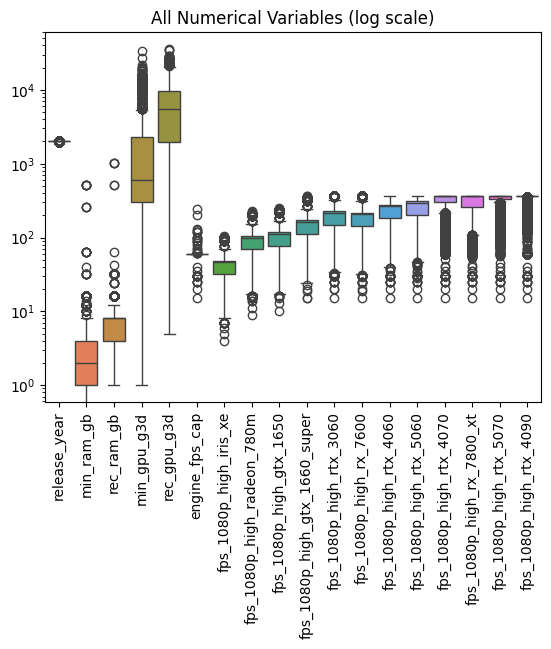

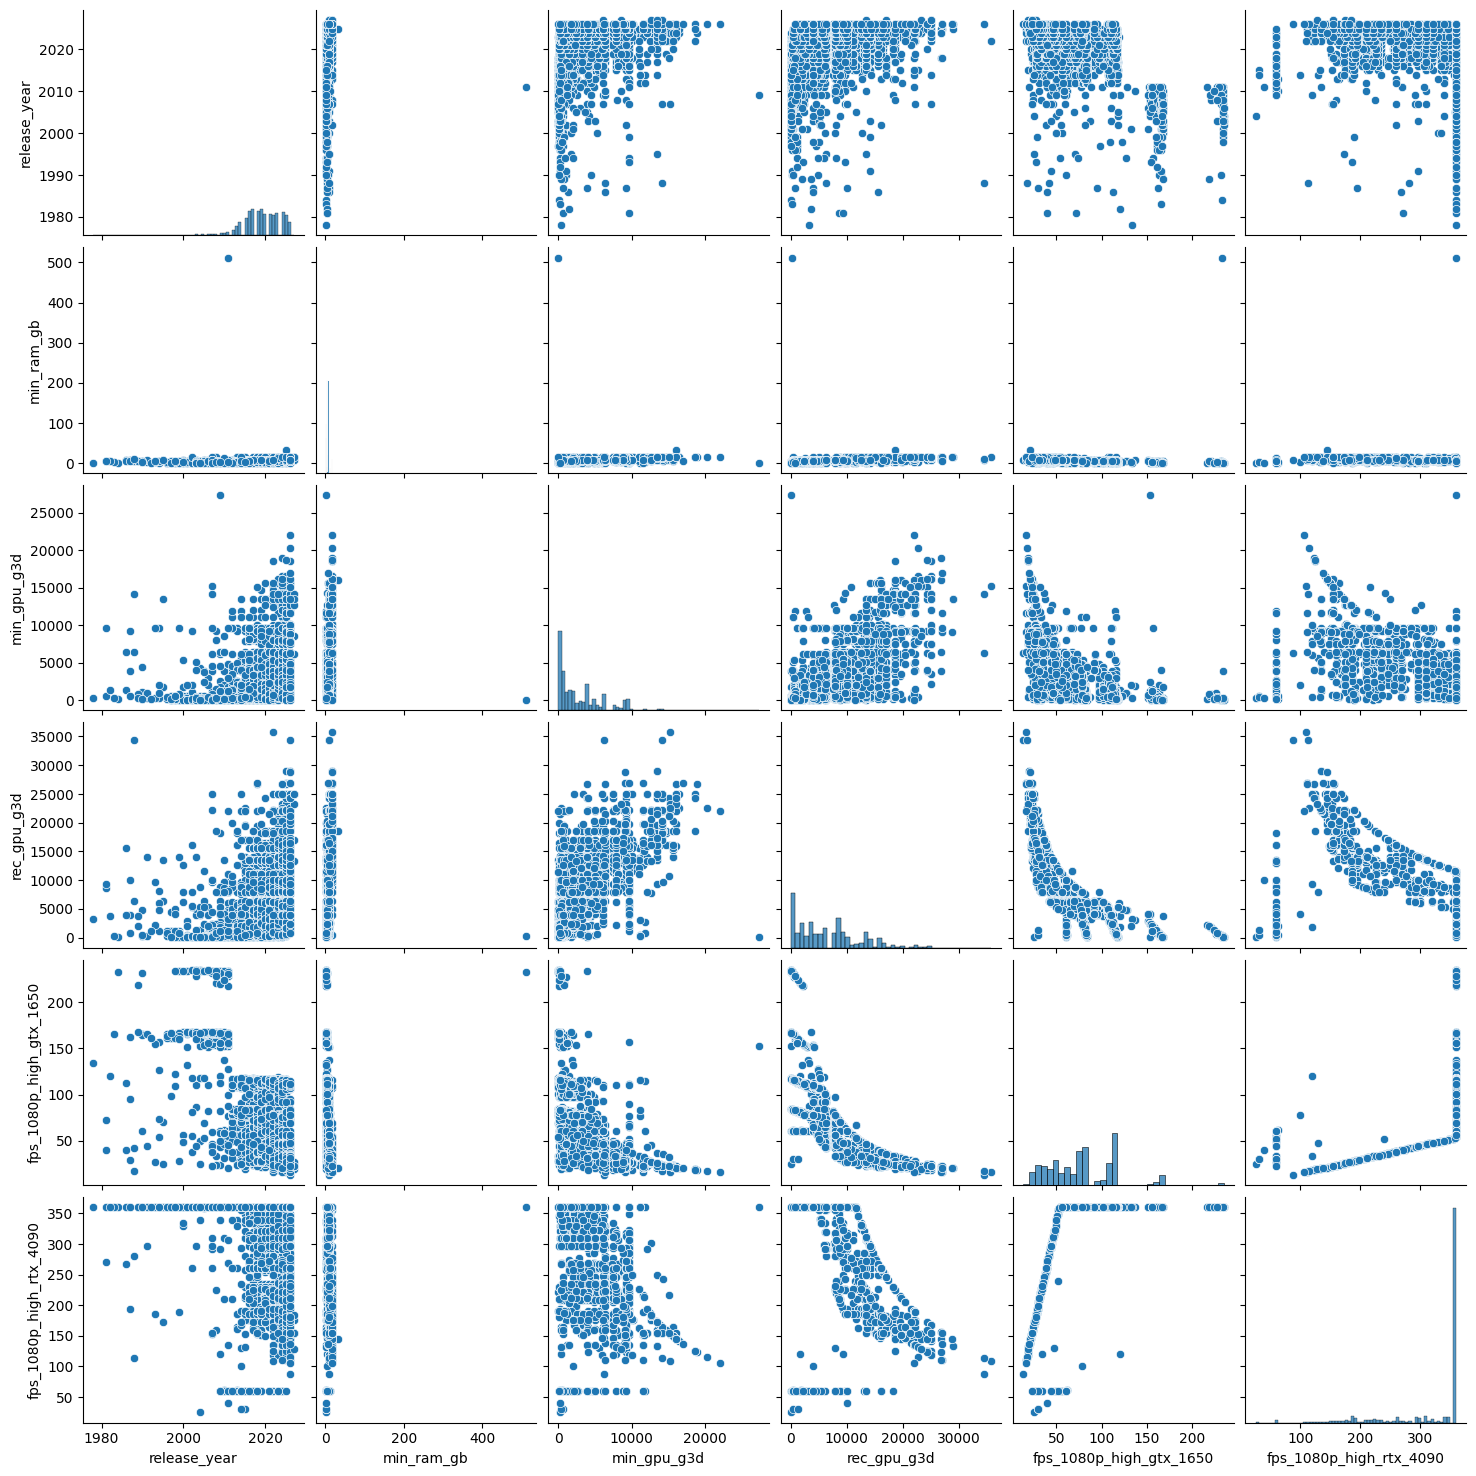

min_cpu                                     1 GHz  1.0 GHz Processor  1.6 GHz  \
min_gpu                                                                         
100% DirectX compatible graphics                3                 71        0   
256 MB VRAM                                     0                  0        0   
3D graphics card compatible with DirectX 7      8                  0        0   
Any GPU                                         1                  0        0   
DirectX 9.0c compatible video card             23                  0        4   
Intel HD 4000                                   0                  0        0   
Intel HD Graphics                               0                  0        7   
NVIDIA GeForce GTX 960                          0                  0        0   
NVIDIA GeForce GTX 970                          0                  0        0   

min_cpu                                     1.8 GHz  1.8 GHz Processor  2 GHz  \
min_gpu                    

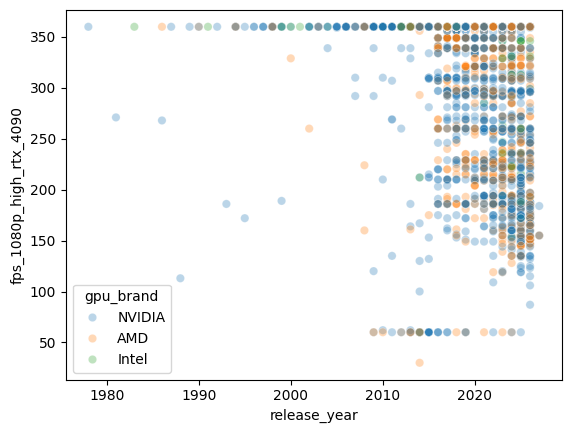

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# url for the dataset
url = "https://huggingface.co/datasets/pcgamebenchmarks/pc-game-system-requirements-fps/resolve/main/games.csv"
games = pd.read_csv(url)

# Drop unhelpful columns
games = games.drop(columns=['steam_appid', 'page_url', 'name'])

# For quantitative variables only
for col in games.select_dtypes('number').columns:
    sns.histplot(data=games, x=col, bins=20)
    plt.title(col)
    plt.show()

# For cagegorical variables only
for col in games.select_dtypes('object').columns:
    sns.countplot(data=games, y=col,
                  order=games[col].value_counts().head(20).index)
    plt.title(col)
    plt.show()

# Print out max, min, mean, median, number of outliers for number
for col in games.select_dtypes('number').columns:
    Q1, Q3 = games[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    outliers = games[(games[col] < Q1 - 1.5*IQR) | (games[col] > Q3 + 1.5*IQR)]

    print(f"\n{col}")
    print("Max:    ", games[col].max())
    print("Min:    ", games[col].min())
    print("Mean:   ", games[col].mean())
    print("Median: ", games[col].median())
    print(f"Outliers: {len(outliers)}")

# Box plot for numerical values
sns.boxplot(data=games.select_dtypes('number'))
plt.yscale('log')
plt.xticks(rotation=90)
plt.title('All Numerical Variables (log scale)')
plt.show()

# Scatter plot for appropriate numerical variables
scatter_cols = ['release_year', 'min_ram_gb', 'min_gpu_g3d',
                'rec_gpu_g3d', 'fps_1080p_high_gtx_1650',
                'fps_1080p_high_rtx_4090']
sns.pairplot(games[scatter_cols].dropna())
plt.show()

# Print the categorical vs categorical value
top_gpus = games['min_gpu'].value_counts().head(10).index
top_cpus = games['min_cpu'].value_counts().head(10).index

ct = pd.crosstab(
    games[games['min_gpu'].isin(top_gpus)]['min_gpu'],
    games[games['min_cpu'].isin(top_cpus)]['min_cpu']
)
print(ct)

# Categorical vs numerical (color)
games['gpu_brand'] = games['rec_gpu'].str.extract(r'(NVIDIA|AMD|Intel)', expand=False)

sns.scatterplot(data=games, x='release_year',
                y='fps_1080p_high_rtx_4090',
                hue='gpu_brand', alpha=0.3)
plt.show()
